#### **This is a challenge Notebook on Bioinformatics:**
---
- Here I write codes and functions to solve some biological questions
- I start with reading fasta files to manipulate sequences in those records

In [82]:
# importing libraries
import pandas as pd
import numpy as np
from collections import Counter
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqUtils import gc_fraction

#### **Assignment 1: Reading Fasta and Fastq Files:**
---
- Add a calculation that determines AT percent:
- Identify which sequence has the highest GC content
- Modify code to print only sequences with GC content greater than 5%

In [40]:
# let's write a function that will calculate AT percent
def at_fraction(sequence):
    sequence = sequence.upper()
    nuc_counts = Counter(sequence)
    at_percent = (nuc_counts["A"]+nuc_counts["T"])/len(sequence)
    return round(at_percent*100,2)

In [41]:
# let's read this fasta file : practice_sequence.fasta :
# We use SeqIO.parse(): This is for reading multiple record file
ids = []
gc_contents =[]
at_contents =[]
length = []
for record in SeqIO.parse("practice_sequence.fasta","fasta"):
    sequence = record.seq.upper()
    gc_percent = round(gc_fraction(sequence)*100,2)
    at_percent = at_fraction(sequence)
    if gc_percent > 50:
        ids.append(record.id)
        length.append(len(sequence))
        gc_contents.append(gc_percent)
        at_contents.append(at_percent)
df = pd.DataFrame(
    {
        "ID":ids,
        "Length":length,
        "GC_Fraction": gc_contents,
        "AT_Fraction":at_contents

    }
)          
df = df.sort_values("GC_Fraction", ascending = False,ignore_index = True)
df

,ID,Length,GC_Fraction,AT_Fraction
0,Ecoli_Gene1,31,61.29,38.71
1,Human_HBA,41,60.98,39.02
2,Human_HBB,42,57.14,42.86
3,Salmonella_Gene1,32,56.25,43.75


In [42]:
# Ecoli_Gene1 has the highest GC content

#### **Quality Scores: Fastq File**
--- 
- Assignment 2:

In [92]:
# let's create an iterable record object
ids = []
mean_qual =[]
proportion = []
lens =[]
recordsq = SeqIO.parse("practice_reads.fastq","fastq")
for record in recordsq:
    # extract read id
    ids.append(record.id)
    # Extract length
    lens.append(len(record.seq))
    # saving quality scores of the reads
    qual = np.array(record.letter_annotations['phred_quality'])
    # calculating mean of quality scores
    mean_qual.append(np.mean(qual))
    # calculating fraction with high quality
    nog30 = qual[qual>= 30]
    fraction = (len(nog30)/len(qual))*100
    proportion.append(fraction)

df = pd.DataFrame(
    {
        "Id": ids,
        "Read_Length":lens,
        "Mean_Quality":mean_qual,
        "Q30_Percentage":proportion
    }
)
df["Classification"] =pd.cut(
    df['Mean_Quality'],
    bins = [0,20,30,np.inf],
    labels=['Low quality','Moderate quality','High quality'],
    right = False
    )
df

,Id,Read_Length,Mean_Quality,Q30_Percentage,Classification
0,read_1,16,40.0,100.0,High quality
1,read_2,16,25.0,50.0,Moderate quality
2,read_3,16,20.0,0.0,Moderate quality


##### **Let's Make A plot of the Quality Scores**
---

In [95]:
# let's make a plot the distribution of quality scores:
quality_scores = []
for record in SeqIO.parse("practice_reads.fastq", "fastq"):
    quality_scores.extend(record.letter_annotations['phred_quality'])
# let's build a list of zeroes up to length of maximum quality scores: let's say 45
qual_count = Counter(quality_scores)

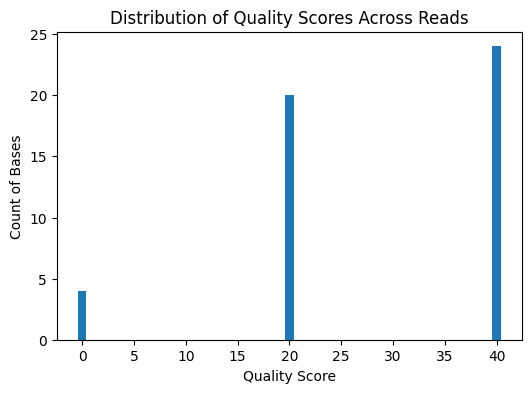

In [97]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.bar(x=qual_count.keys(), height=qual_count.values())
plt.xlabel("Quality Score")
plt.ylabel("Count of Bases")
plt.title("Distribution of Quality Scores Across Reads");

##### **Quality By Position:**

In [101]:
positions = np.array(
    [
    record.letter_annotations["phred_quality"]
    for record in SeqIO.parse("practice_reads.fastq", "fastq")
]
)

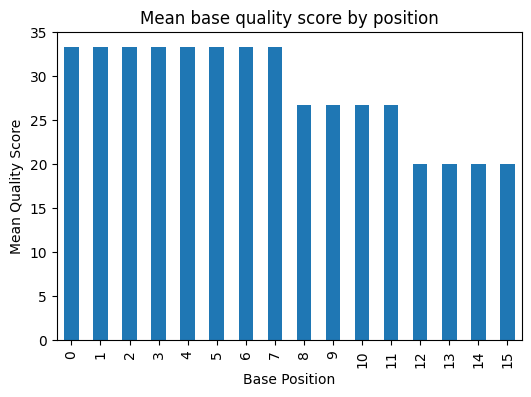

In [115]:
# let's calculate mean: columnwise, that gives us mean by read position:
# In bioinformatics, this helps as find read cyles eith problems; it informs triming bad reads
pos_mean = np.mean(positions, axis = 0)
pos_mean = pd.Series(pos_mean)
# let's plot it:
plt.figure(figsize = (6,4))
pos_mean.plot(kind = "bar")
plt.xlabel("Base Position")
plt.ylabel("Mean Quality Score")
plt.title("Mean base quality score by position");

#### **Assignment 4: FASTQ Quality Filtering and Trimming**
---
- How to remove low-quality sequencing reads
- How to trim low-quality bases from read ends.
- How to implement sliding-window quality filtering.
- How to identify and remove sequencing adapters.
- How to compare FASTQ quality before and after trimming.

#### **Understanding the problem**
---
Imagine you have received 10,000 sequencing reads from a malaria parasite DNA sequencing experiment.
Some reads may have:
- High-quality nucleotide calls throughout.
- Poor-quality bases towards the 3′ end.
- Poor-quality bases at both ends.
- Very short sequences.
- Sequencing adapter contamination.

In [125]:
# let's collect Reads into an Array to compute Per Read quality score and Per Base quality Score:
qual_by_position = np.array(
    [
    record.letter_annotations['phred_quality']
    for record in SeqIO.parse("raw_reads.fastq","fastq")
    ]
    )
# let's have a look
qual_by_position[:2]

array([[35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35,
        35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35,
        35, 35, 35, 35, 35, 35, 35, 35],
       [35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35,
        35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 10, 10,
        10, 10, 10, 10, 10, 10, 10, 10]])

In [161]:
read_ids = np.array(
    [
        record.id
        for record in SeqIO.parse("raw_reads.fastq", "fastq")
    ]
)
read_ids

array(['read_1', 'read_2', 'read_3', 'read_4', 'read_5', 'read_6'],
      dtype='<U6')

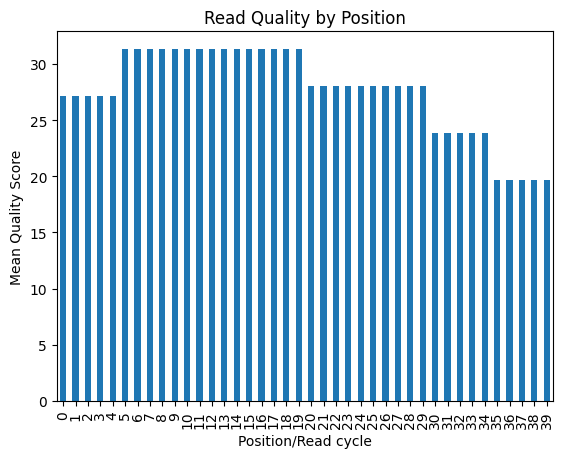

In [136]:
# let's calculate quality by read cycle or base position:
mean_pos_qual = np.mean(qual_by_position, axis = 0)
pd.Series(mean_pos_qual).plot(kind = "bar")
plt.xlabel("Position/Read cycle")
plt.ylabel("Mean Quality Score")
plt.title("Read Quality by Position");

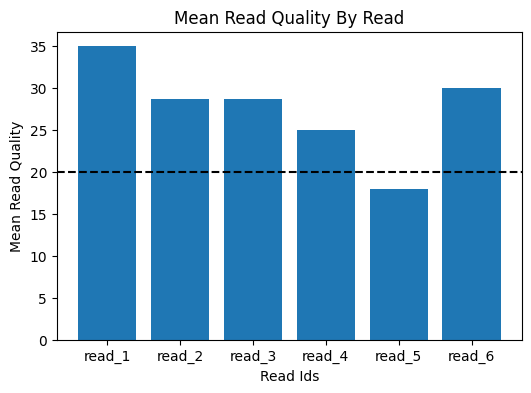

In [164]:
# quality per read:
qual_per_read = np.mean(qual_by_position,axis = 1)
mean_per_read = pd.Series(qual_per_read)
indices = list(mean_per_read.index+1)
plt.figure(figsize = (6,4))
plt.bar(
    x = read_ids,
    height = mean_per_read.values
)
plt.axhline(y = 20, color = "black", linestyle = "--")
plt.xlabel("Read Ids")
plt.ylabel("Mean Read Quality")
plt.title("Mean Read Quality By Read");